In [18]:
from collections import deque

# Узел BST — простой контейнер
class BSTNode:
    pass

def make_bst_node(key):
    node = BSTNode()
    node.key = key
    node.left = None
    node.right = None
    return node

class BST:
    # ---- Вставка ----
    def insert(self, key):
        parent = None
        current = getattr(self, "root", None)
        while current is not None:
            parent = current
            if key < current.key:
                current = current.left
            elif key > current.key:
                current = current.right
            else:
                return  # дубликат — ничего не делаем
        new_node = make_bst_node(key)
        if parent is None:
            self.root = new_node
        elif key < parent.key:
            parent.left = new_node
        else:
            parent.right = new_node

    # ---- Поиск ----
    def search(self, key):
        current = getattr(self, "root", None)
        while current is not None:
            if key == current.key:
                return current
            current = current.left if key < current.key else current.right
        return None

    # ---- Минимум / максимум ----
    def find_min(self, start_node=None):
        cur = getattr(self, "root", None) if start_node is None else start_node
        while cur and cur.left:
            cur = cur.left
        return cur

    def find_max(self, start_node=None):
        cur = getattr(self, "root", None) if start_node is None else start_node
        while cur and cur.right:
            cur = cur.right
        return cur

    # ---- Удаление ----
    def delete(self, key):
        def delete_rec(node, key):
            if node is None:
                return None
            if key < node.key:
                node.left = delete_rec(node.left, key)
            elif key > node.key:
                node.right = delete_rec(node.right, key)
            else:
                if node.left is None: return node.right
                if node.right is None: return node.left
                succ = node.right
                while succ.left:
                    succ = succ.left
                node.key = succ.key
                node.right = delete_rec(node.right, succ.key)
            return node
        self.root = delete_rec(getattr(self, "root", None), key)

    # ---- Обходы ----
    def inorder(self):
        res = []
        def _in(node):
            if node:
                _in(node.left)
                res.append(node.key)
                _in(node.right)
        _in(getattr(self, "root", None))
        return res

    def preorder(self):
        res = []
        def _pre(node):
            if node:
                res.append(node.key)
                _pre(node.left)
                _pre(node.right)
        _pre(getattr(self, "root", None))
        return res

    def postorder(self):
        res = []
        def _post(node):
            if node:
                _post(node.left)
                _post(node.right)
                res.append(node.key)
        _post(getattr(self, "root", None))
        return res

    def breadth_first(self):
        res = []
        root = getattr(self, "root", None)
        if not root:
            return res
        q = deque([root])
        while q:
            n = q.popleft()
            res.append(n.key)
            if n.left: q.append(n.left)
            if n.right: q.append(n.right)
        return res


In [19]:
def test_bst_simple():
    print("=== Тест BST: начинаем ===")
    tree = BST()
    tree.root = None  # явно инициализируем корень

    # вставляем значения
    for v in [50, 30, 70, 20, 40, 60, 80]:
        tree.insert(v)

    # поиск
    node = tree.search(60)
    print("search(60):", node.key if node else None)

    node = tree.search(470)
    print("search(470):", node.key if node else None)

    # min / max
    print("find_min():", tree.find_min().key if tree.find_min() else None)
    print("find_max():", tree.find_max().key if tree.find_max() else None)

    # обходы
    print("inorder:", tree.inorder())      # отсортированный список
    print("preorder:", tree.preorder())
    print("postorder:", tree.postorder())
    print("breadth_first:", tree.breadth_first())

    # удаления
    tree.delete(20)   # удаляем лист
    print("После delete(20), inorder:", tree.inorder())

    tree.insert(25)
    tree.delete(30)   # удаляем узел с одним ребёнком
    print("После delete(30), inorder:", tree.inorder())

    tree.delete(50)   # удаляем корень (два ребёнка)
    print("После delete(50), inorder:", tree.inorder())

    print("=== Тест BST: завершён ===")


# запуск теста
test_bst_simple()


=== Тест BST: начинаем ===
search(60): 60
search(470): None
find_min(): 20
find_max(): 80
inorder: [20, 30, 40, 50, 60, 70, 80]
preorder: [50, 30, 20, 40, 70, 60, 80]
postorder: [20, 40, 30, 60, 80, 70, 50]
breadth_first: [50, 30, 70, 20, 40, 60, 80]
После delete(20), inorder: [30, 40, 50, 60, 70, 80]
После delete(30), inorder: [25, 40, 50, 60, 70, 80]
После delete(50), inorder: [25, 40, 60, 70, 80]
=== Тест BST: завершён ===


n=   100  avg_h= 13.48  std= 1.48  repeats=60
n=   866  avg_h= 21.68  std= 1.67  repeats=60
n=  1633  avg_h= 24.77  std= 2.26  repeats=30
n=  2400  avg_h= 25.77  std= 2.19  repeats=30
n=  3166  avg_h= 27.40  std= 2.33  repeats=30
n=  3933  avg_h= 26.80  std= 1.68  repeats=30
n=  4700  avg_h= 28.07  std= 2.02  repeats=30
n=  5466  avg_h= 29.40  std= 2.42  repeats=15
n=  6233  avg_h= 28.93  std= 1.73  repeats=15
n=  7000  avg_h= 29.87  std= 2.19  repeats=15
n=  7766  avg_h= 30.00  std= 1.46  repeats=15
n=  8533  avg_h= 30.87  std= 1.78  repeats=15
n=  9300  avg_h= 30.40  std= 1.62  repeats=15
n= 10066  avg_h= 32.38  std= 1.93  repeats=8
n= 10833  avg_h= 31.62  std= 1.87  repeats=8
n= 11600  avg_h= 31.12  std= 1.17  repeats=8
n= 12366  avg_h= 31.75  std= 1.71  repeats=8
n= 13133  avg_h= 31.50  std= 1.73  repeats=8
n= 13900  avg_h= 32.38  std= 1.49  repeats=8
n= 14666  avg_h= 33.50  std= 2.29  repeats=8
n= 15433  avg_h= 31.88  std= 1.69  repeats=8
n= 16200  avg_h= 32.62  std= 1.11  repeats

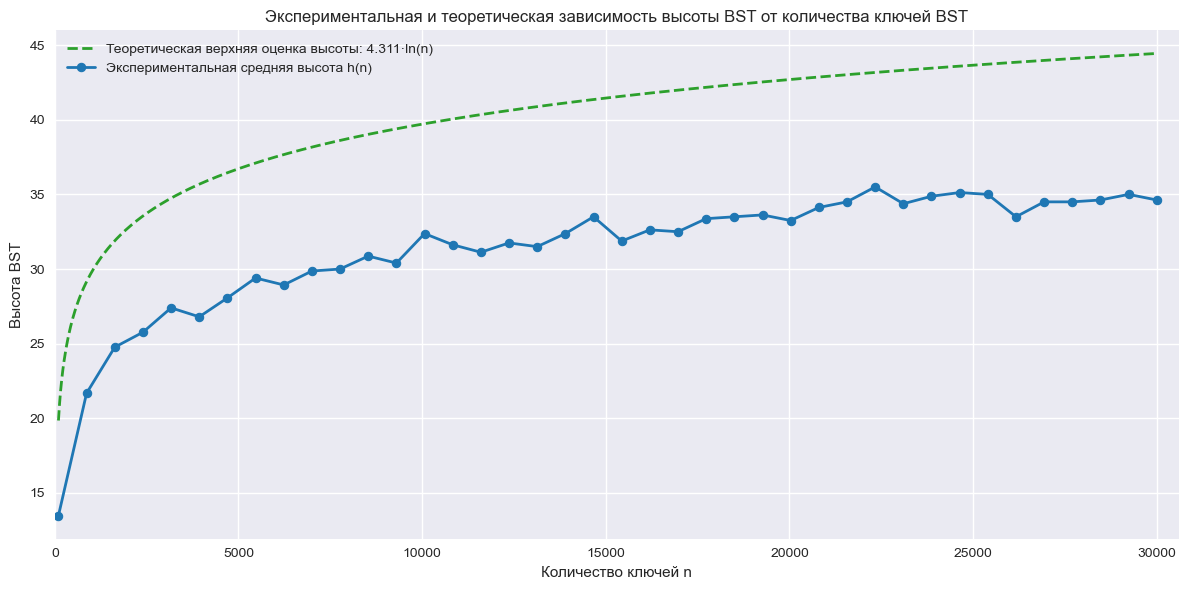

In [62]:
# Вставьте после определения класса BST и запустите
import random
import math
import statistics
import matplotlib.pyplot as plt
import numpy as np
from time import perf_counter

# ---------- Параметры ----------
max_n = 30000
points_count = 40                      # число равномерно распределённых точек
sample_ns = list(map(int, np.linspace(100, max_n, points_count, dtype=int)))
sample_ns = sorted(list(dict.fromkeys(sample_ns)))  # убрать дубликаты, если есть

def repeats_for(n):
    if n <= 1000:
        return 60
    if n <= 5000:
        return 30
    if n <= 10000:
        return 15
    return 8

seed = 20251203

# ---------- Вспомогательные функции ----------
def tree_height(tree):
    def _h(node):
        if node is None:
            return 0
        return 1 + max(_h(getattr(node, "left", None)), _h(getattr(node, "right", None)))
    return _h(getattr(tree, "root", None))

def measure_avg_height(n, repeats, seed_base):
    rng = random.Random(int(seed_base))
    heights = []
    for _ in range(repeats):
        keys = rng.sample(range(1, 10 * n), n)   # уникальные ключи
        tree = BST()
        tree.root = None
        for k in keys:
            tree.insert(k)
        heights.append(tree_height(tree))
    return statistics.mean(heights), statistics.pstdev(heights)

# ---------- Измерения ----------
results = []
t0 = perf_counter()
for n in sample_ns:
    reps = repeats_for(n)
    avg_h, std_h = measure_avg_height(n, reps, seed + int(n))
    results.append((int(n), float(avg_h), float(std_h), int(reps)))
    print(f"n={n:6d}  avg_h={avg_h:6.2f}  std={std_h:5.2f}  repeats={reps}")
t1 = perf_counter()
print(f"Время измерений: {t1-t0:.1f} с")

# ---------- Подготовка данных ----------
x_pts = [r[0] for r in results]
y_pts = [r[1] for r in results]

# теоретическая кривая (гладкая) для случайного BST: 4.311 * ln(n)
theory_ln_coeff = 4.311
xs = np.linspace(min(x_pts), max(x_pts), 1000)
theory_vals = theory_ln_coeff * np.log(xs)

# ---------- Построение графика (точки соединены линией) ----------
plt.style.use("seaborn-v0_8")
plt.figure(figsize=(12,6))

# теоретическая гладкая линия
plt.plot(xs, theory_vals, color='tab:green', linestyle='--', linewidth=2,
         label=f'Теоретическая верхняя оценка высоты: {theory_ln_coeff}·ln(n)')

# экспериментальная линия: точки соединены одной линией и отмечены маркерами
plt.plot(x_pts, y_pts, color='tab:blue', marker='o', linestyle='-', linewidth=2, markersize=6,
         markeredgewidth=0.8, markerfacecolor='tab:blue',
         label='Экспериментальная средняя высота h(n)')

plt.xlabel('Количество ключей n')
plt.ylabel('Высота BST')
plt.title('Экспериментальная и теоретическая зависимость высоты BST от количества ключей BST')
plt.xlim(0, max(x_pts) * 1.02)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [44]:
# Cell 3: AVL 
from collections import deque

class AVLNode:
    pass

def make_avl_node(key):
    node = AVLNode()
    node.key = key
    node.left = None
    node.right = None
    node.height = 1
    return node

class AVLTree:
    # вспомогательные
    def height_of(self, node):
        return node.height if node else 0

    def update_height(self, node):
        node.height = 1 + max(self.height_of(node.left), self.height_of(node.right))

    def balance_factor(self, node):
        return self.height_of(node.left) - self.height_of(node.right)

    # повороты
    def rotate_right(self, y):
        x = y.left
        if x is None:
            return y
        y.left = x.right
        x.right = y
        self.update_height(y)
        self.update_height(x)
        return x

    def rotate_left(self, x):
        y = x.right
        if y is None:
            return x
        x.right = y.left
        y.left = x
        self.update_height(x)
        self.update_height(y)
        return y

    def rebalance_node(self, node):
        self.update_height(node)
        bf = self.balance_factor(node)
        # LL
        if bf > 1 and self.balance_factor(node.left) >= 0:
            return self.rotate_right(node)
        # LR
        if bf > 1 and self.balance_factor(node.left) < 0:
            node.left = self.rotate_left(node.left)
            return self.rotate_right(node)
        # RR
        if bf < -1 and self.balance_factor(node.right) <= 0:
            return self.rotate_left(node)
        # RL
        if bf < -1 and self.balance_factor(node.right) > 0:
            node.right = self.rotate_right(node.right)
            return self.rotate_left(node)
        return node

    # вставка (рекурсивно)
    def insert(self, key):
        def insert_rec(node, key):
            if node is None:
                return make_avl_node(key)
            if key < node.key:
                node.left = insert_rec(node.left, key)
            elif key > node.key:
                node.right = insert_rec(node.right, key)
            else:
                return node
            return self.rebalance_node(node)
        self.root = insert_rec(getattr(self, "root", None), key)

    # поиск
    def search(self, key):
        cur = getattr(self, "root", None)
        while cur:
            if key == cur.key:
                return cur
            cur = cur.left if key < cur.key else cur.right
        return None

    # удаление (рекурсивно)
    def delete(self, key):
        def min_node(node):
            while node.left:
                node = node.left
            return node

        def delete_rec(node, key):
            if node is None:
                return None
            if key < node.key:
                node.left = delete_rec(node.left, key)
            elif key > node.key:
                node.right = delete_rec(node.right, key)
            else:
                if node.left is None:
                    return node.right
                if node.right is None:
                    return node.left
                succ = min_node(node.right)
                node.key = succ.key
                node.right = delete_rec(node.right, succ.key)
            return self.rebalance_node(node) if node else None
        self.root = delete_rec(getattr(self, "root", None), key)

    # обходы
    def inorder(self):
        result = []
        def inorder_recursive(node):
            if node is None:
                return
            inorder_recursive(node.left)
            result.append(node.key)
            inorder_recursive(node.right)
        inorder_recursive(getattr(self, "root", None))
        return result

    def preorder(self):
        result = []
        def preorder_recursive(node):
            if node is None:
                return
            result.append(node.key)
            preorder_recursive(node.left)
            preorder_recursive(node.right)
        preorder_recursive(getattr(self, "root", None))
        return result

    def postorder(self):
        result = []
        def postorder_recursive(node):
            if node is None:
                return
            postorder_recursive(node.left)
            postorder_recursive(node.right)
            result.append(node.key)
        postorder_recursive(getattr(self, "root", None))
        return result

    def breadth_first(self):
        result = []
        root = getattr(self, "root", None)
        if root is None:
            return result
        q = deque([root])
        while q:
            n = q.popleft()
            result.append(n.key)
            if n.left: q.append(n.left)
            if n.right: q.append(n.right)
        return result


In [7]:
def test_avl_simple():
    print("=== Тест AVL: начинаем ===")
    tree = AVLTree()
    tree.root = None  # явно инициализируем корень

    # тесты для поворотов
    cases = {
        "RR": [10, 20, 30],
        "LL": [30, 20, 10],
        "LR": [30, 10, 20],
        "RL": [10, 30, 20]
    }
    for name, seq in cases.items():
        t = AVLTree()
        t.root = None
        for v in seq:
            t.insert(v)
        print(f"{name} вставка {seq} -> inorder: {t.inorder()}, breadth: {t.breadth_first()}")

    # более сложный набор
    tree = AVLTree()
    tree.root = None
    for v in [50, 30, 70, 20, 40, 60, 80, 25, 35, 65]:
        tree.insert(v)
    print("После сложных вставок, inorder:", tree.inorder())
    print("Breadth-first:", tree.breadth_first())

    # удаления
    tree.delete(20)
    print("После delete(20), inorder:", tree.inorder())

    tree.delete(30)
    print("После delete(30), postorder:", tree.postorder())

    tree.delete(50)
    print("После delete(50), preorder:", tree.preorder())

    print("Итог в ширину:", tree.breadth_first())

    # поиск
    node = tree.search(60)
    print("search(60):", node.key if node else None)

    node = tree.search(470)
    print("search(470):", node.key if node else None)

    print("=== Тест AVL: завершён ===")

    # LL-case: последовательные вставки слева (правый поворот)
    tree1 = AVLTree()
    tree1.root = None
    for v in [30, 20, 10, 5]:
        tree1.insert(v)
    print("LL-case inorder:", tree1.inorder())
    print("LL-case breadth_first:", tree1.breadth_first())

    # RR-case: последовательные вставки справа (левый поворот)
    tree2 = AVLTree()
    tree2.root = None
    for v in [10, 20, 30, 40]:
        tree2.insert(v)
    print("RR-case inorder:", tree2.inorder())
    print("RR-case breadth_first:", tree2.breadth_first())

    # LR-case: вставки вызывают левый+правый поворот
    tree3 = AVLTree()
    tree3.root = None
    for v in [30, 10, 20, 25]:
        tree3.insert(v)
    print("LR-case inorder:", tree3.inorder())
    print("LR-case breadth_first:", tree3.breadth_first())

    # RL-case: вставки вызывают правый+левый поворот
    tree4 = AVLTree()
    tree4.root = None
    for v in [10, 30, 20, 15]:
        tree4.insert(v)
    print("RL-case inorder:", tree4.inorder())
    print("RL-case breadth_first:", tree4.breadth_first())

    # Большой набор ключей для комплексной проверки
    tree5 = AVLTree()
    tree5.root = None
    for v in [50, 30, 70, 20, 100, 56, 81, 10, 37, 62, 34, 45, 15, 75, 85]:
        tree5.insert(v)
    print("Big set inorder:", tree5.inorder())
    print("Big set breadth_first:", tree5.breadth_first())
    tree5.delete(20)
    print("После delete(20), breadth_first:", tree5.breadth_first())

    print("=== Конец теста AVL поворотов ===")


# запуск теста
test_avl_simple()


=== Тест AVL: начинаем ===
RR вставка [10, 20, 30] -> inorder: [10, 20, 30], breadth: [20, 10, 30]
LL вставка [30, 20, 10] -> inorder: [10, 20, 30], breadth: [20, 10, 30]
LR вставка [30, 10, 20] -> inorder: [10, 20, 30], breadth: [20, 10, 30]
RL вставка [10, 30, 20] -> inorder: [10, 20, 30], breadth: [20, 10, 30]
После сложных вставок, inorder: [20, 25, 30, 35, 40, 50, 60, 65, 70, 80]
Breadth-first: [50, 30, 70, 20, 40, 60, 80, 25, 35, 65]
После delete(20), inorder: [25, 30, 35, 40, 50, 60, 65, 70, 80]
После delete(30), postorder: [25, 40, 35, 65, 60, 80, 70, 50]
После delete(50), preorder: [60, 35, 25, 40, 70, 65, 80]
Итог в ширину: [60, 35, 70, 25, 40, 65, 80]
search(60): 60
search(470): None
=== Тест AVL: завершён ===
LL-case inorder: [5, 10, 20, 30]
LL-case breadth_first: [20, 10, 30, 5]
RR-case inorder: [10, 20, 30, 40]
RR-case breadth_first: [20, 10, 30, 40]
LR-case inorder: [10, 20, 25, 30]
LR-case breadth_first: [20, 10, 30, 25]
RL-case inorder: [10, 15, 20, 30]
RL-case breadth

n=   100  avg_h=  8.00  std= 0.00  repeats=60
n=   866  avg_h= 11.90  std= 0.30  repeats=60
n=  1633  avg_h= 12.97  std= 0.18  repeats=30
n=  2400  avg_h= 13.40  std= 0.49  repeats=30
n=  3166  avg_h= 14.00  std= 0.00  repeats=30
n=  3933  avg_h= 14.17  std= 0.37  repeats=30
n=  4700  avg_h= 14.67  std= 0.47  repeats=30
n=  5466  avg_h= 15.00  std= 0.00  repeats=15
n=  6233  avg_h= 15.00  std= 0.00  repeats=15
n=  7000  avg_h= 15.07  std= 0.25  repeats=15
n=  7766  avg_h= 15.47  std= 0.50  repeats=15
n=  8533  avg_h= 15.73  std= 0.44  repeats=15
n=  9300  avg_h= 15.93  std= 0.25  repeats=15
n= 10066  avg_h= 16.00  std= 0.00  repeats=8
n= 10833  avg_h= 16.00  std= 0.00  repeats=8
n= 11600  avg_h= 16.00  std= 0.00  repeats=8
n= 12366  avg_h= 16.12  std= 0.33  repeats=8
n= 13133  avg_h= 16.50  std= 0.50  repeats=8
n= 13900  avg_h= 16.38  std= 0.48  repeats=8
n= 14666  avg_h= 16.62  std= 0.48  repeats=8
n= 15433  avg_h= 16.75  std= 0.43  repeats=8
n= 16200  avg_h= 17.00  std= 0.00  repeats

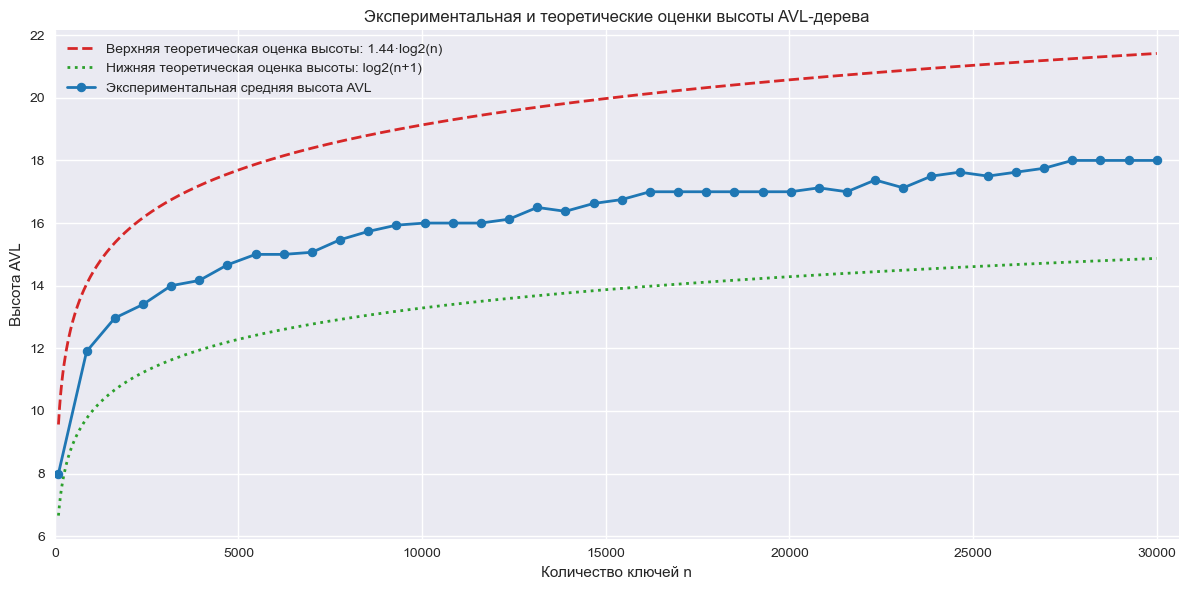

In [64]:
# Эксперимент и график для AVL: экспериментальная кривая + верхняя и нижняя теоретические оценки
import random
import math
import statistics
import matplotlib.pyplot as plt
import numpy as np
from time import perf_counter

# ---------- Параметры ----------
max_n = 30000
points_count = 40                      # число равномерно распределённых точек
sample_ns = list(map(int, np.linspace(100, max_n, points_count, dtype=int)))
sample_ns = sorted(list(dict.fromkeys(sample_ns)))  # убрать дубликаты, если есть

def repeats_for(n):
    if n <= 1000:
        return 60
    if n <= 5000:
        return 30
    if n <= 10000:
        return 15
    return 8

seed = 20251203

# ---------- Вспомогательные функции ----------
def measure_avg_height_avl(n, repeats, seed_base):
    rng = random.Random(int(seed_base))
    heights = []
    for _ in range(repeats):
        keys = rng.sample(range(1, 10 * n), n)
        tree = AVLTree()
        tree.root = None
        for k in keys:
            tree.insert(k)
        # высота через поле height корня (в реализации height хранится в узлах)
        h = tree.height_of(getattr(tree, "root", None))
        heights.append(h)
    return statistics.mean(heights), statistics.pstdev(heights)

# ---------- Измерения ----------
results = []
t0 = perf_counter()
for n in sample_ns:
    reps = repeats_for(n)
    avg_h, std_h = measure_avg_height_avl(n, reps, seed + int(n))
    results.append((int(n), float(avg_h), float(std_h), int(reps)))
    print(f"n={n:6d}  avg_h={avg_h:6.2f}  std={std_h:5.2f}  repeats={reps}")
t1 = perf_counter()
print(f"Время измерений: {t1-t0:.1f} с")

# ---------- Подготовка данных ----------
x_pts = [r[0] for r in results]
y_pts = [r[1] for r in results]

# теоретические кривые
# Верхняя теоретическая оценка (AVL worst-case): ~ 1.44 * log2(n)
upper_coeff = 1.44
# Нижняя теоретическая оценка (идеально сбалансированное дерево): log2(n+1)
xs = np.linspace(min(x_pts), max(x_pts), 1000)
upper_vals = [upper_coeff * math.log2(x) for x in xs]
lower_vals = [math.log2(x + 1) for x in xs]   # log2(n+1)

# ---------- Построение графика ----------
plt.style.use("seaborn-v0_8")
plt.figure(figsize=(12,6))

# теоретические линии
plt.plot(xs, upper_vals, color='tab:red', linestyle='--', linewidth=2,
         label='Верхняя теоретическая оценка высоты: 1.44·log2(n)')
plt.plot(xs, lower_vals, color='tab:green', linestyle=':', linewidth=2,
         label='Нижняя теоретическая оценка высоты: log2(n+1)')

# экспериментальная линия: точки соединены и отмечены маркерами
plt.plot(x_pts, y_pts, color='tab:blue', marker='o', linestyle='-', linewidth=2, markersize=6,
         markeredgewidth=0.8, markerfacecolor='tab:blue',
         label='Экспериментальная средняя высота AVL')

plt.xlabel('Количество ключей n')
plt.ylabel('Высота AVL')
plt.title('Экспериментальная и теоретические оценки высоты AVL-дерева')
plt.xlim(0, max(x_pts) * 1.02)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [11]:
from collections import deque

RED = "R"
BLACK = "B"


class RBNode:
    def __init__(self, key=None, parent=None, color=BLACK):
        self.key = key
        self.left = None
        self.right = None
        self.parent = parent
        self.color = color

    def __repr__(self):
        return f"RBNode({self.key},{self.color})"


# Единый NIL-узел
NIL = RBNode(key=None, parent=None, color=BLACK)
NIL.left = NIL.right = NIL.parent = NIL


class RedBlackTree:
    def __init__(self):
        self.root = NIL

    # ---- Поиск ----
    def search(self, key):
        node = self.root
        while node is not NIL and node.key != key:
            node = node.left if key < node.key else node.right
        return None if node is NIL else node

    def tree_minimum(self, node=None):
        node = self.root if node is None else node
        if node is NIL:
            return None
        while node.left is not NIL:
            node = node.left
        return node

    def tree_maximum(self, node=None):
        node = self.root if node is None else node
        if node is NIL:
            return None
        while node.right is not NIL:
            node = node.right
        return node

    # ---- Повороты ----
    def left_rotate(self, x):
        y = x.right
        if y is NIL:
            return
        x.right = y.left
        if y.left is not NIL:
            y.left.parent = x
        y.parent = x.parent
        if x.parent is NIL:
            self.root = y
        elif x is x.parent.left:
            x.parent.left = y
        else:
            x.parent.right = y
        y.left = x
        x.parent = y

    def right_rotate(self, y):
        x = y.left
        if x is NIL:
            return
        y.left = x.right
        if x.right is not NIL:
            x.right.parent = y
        x.parent = y.parent
        if y.parent is NIL:
            self.root = x
        elif y is y.parent.right:
            y.parent.right = x
        else:
            y.parent.left = x
        x.right = y
        y.parent = x

    # ---- Вставка ----
    def insert(self, key):
        new_node = RBNode(key=key, parent=NIL, color=RED)
        new_node.left = new_node.right = NIL
        parent = NIL
        current = self.root
        while current is not NIL:
            parent = current
            if new_node.key < current.key:
                current = current.left
            elif new_node.key > current.key:
                current = current.right
            else:
                return  # дубликат
        new_node.parent = parent
        if parent is NIL:
            self.root = new_node
        elif new_node.key < parent.key:
            parent.left = new_node
        else:
            parent.right = new_node
        self._insert_fixup(new_node)

    def _insert_fixup(self, z):
        while z.parent.color == RED:
            if z.parent is z.parent.parent.left:
                uncle = z.parent.parent.right
                if uncle.color == RED:
                    z.parent.color = BLACK
                    uncle.color = BLACK
                    z.parent.parent.color = RED
                    z = z.parent.parent
                else:
                    if z is z.parent.right:
                        z = z.parent
                        self.left_rotate(z)
                    z.parent.color = BLACK
                    z.parent.parent.color = RED
                    self.right_rotate(z.parent.parent)
            else:
                uncle = z.parent.parent.left
                if uncle.color == RED:
                    z.parent.color = BLACK
                    uncle.color = BLACK
                    z.parent.parent.color = RED
                    z = z.parent.parent
                else:
                    if z is z.parent.left:
                        z = z.parent
                        self.right_rotate(z)
                    z.parent.color = BLACK
                    z.parent.parent.color = RED
                    self.left_rotate(z.parent.parent)
        self.root.color = BLACK

    # ---- Удаление ----
    def _transplant(self, u, v):
        if u.parent is NIL:
            self.root = v
        elif u is u.parent.left:
            u.parent.left = v
        else:
            u.parent.right = v
        v.parent = u.parent

    def delete(self, key):
        z = self.search(key)
        if not z:
            return
        y = z
        y_original_color = y.color
        if z.left is NIL:
            x = z.right
            self._transplant(z, z.right)
        elif z.right is NIL:
            x = z.left
            self._transplant(z, z.left)
        else:
            y = z.right
            while y.left is not NIL:
                y = y.left
            y_original_color = y.color
            x = y.right
            if y.parent is z:
                x.parent = y
            else:
                self._transplant(y, y.right)
                y.right = z.right
                y.right.parent = y
            self._transplant(z, y)
            y.left = z.left
            y.left.parent = y
            y.color = z.color
        if y_original_color == BLACK:
            self._delete_fixup(x)

    def _delete_fixup(self, x):
        while x != self.root and x.color == BLACK:
            if x is x.parent.left:
                w = x.parent.right
                if w.color == RED:
                    w.color = BLACK
                    x.parent.color = RED
                    self.left_rotate(x.parent)
                    w = x.parent.right
                if w.left.color == BLACK and w.right.color == BLACK:
                    w.color = RED
                    x = x.parent
                else:
                    if w.right.color == BLACK:
                        w.left.color = BLACK
                        w.color = RED
                        self.right_rotate(w)
                        w = x.parent.right
                    w.color = x.parent.color
                    x.parent.color = BLACK
                    w.right.color = BLACK
                    self.left_rotate(x.parent)
                    x = self.root
            else:
                w = x.parent.left
                if w.color == RED:
                    w.color = BLACK
                    x.parent.color = RED
                    self.right_rotate(x.parent)
                    w = x.parent.left
                if w.right.color == BLACK and w.left.color == BLACK:
                    w.color = RED
                    x = x.parent
                else:
                    if w.left.color == BLACK:
                        w.right.color = BLACK
                        w.color = RED
                        self.left_rotate(w)
                        w = x.parent.left
                    w.color = x.parent.color
                    x.parent.color = BLACK
                    w.left.color = BLACK
                    self.right_rotate(x.parent)
                    x = self.root
        x.color = BLACK

    # ---- Обходы ----
    def inorder(self):
        res = []
        def _in(node):
            if node is NIL:
                return
            _in(node.left)
            res.append(node.key)
            _in(node.right)
        _in(self.root)
        return res

    def breadth_first(self):
        res = []
        if self.root is NIL:
            return res
        q = deque([self.root])
        while q:
            node = q.popleft()
            res.append((node.key, node.color))
            if node.left is not NIL:
                q.append(node.left)
            if node.right is not NIL:
                q.append(node.right)
        return res

    # ---- Проверка свойств ----
    def validate_rb_properties(self) -> bool:

    # Проверка свойств красно-чёрного дерева:
    #   1) У каждого узла есть цвет (RED или BLACK)
    #   2) Корень чёрный
    #   3) Все листья (NIL) чёрные
    #   4) У красного узла оба потомка — чёрные
    #   5) Для любого узла все простые пути до NIL содержат одинаковое число чёрных узлов

        if self.root is NIL:
            return True

        # 2) Корень чёрный
        if self.root.color != BLACK:
            return False

        # 4) У красного узла оба потомка — чёрные
        def no_red_parent_child(node):
            if node is NIL:
                return True
            if node.color == RED:
                if node.left.color == RED or node.right.color == RED:
                    return False
            return no_red_parent_child(node.left) and no_red_parent_child(node.right)

        if not no_red_parent_child(self.root):
            return False

        # 5) Проверка одинаковой чёрной высоты на всех путях
        black_counts = []

        def dfs_count(node, count):
            if node.color == BLACK:
                count += 1
            if node is NIL:
                black_counts.append(count)
                return
            dfs_count(node.left, count)
            dfs_count(node.right, count)

        dfs_count(self.root, 0)

        return len(set(black_counts)) == 1



In [13]:
def test_rbt_simple():
    print("=== Тест Red-Black Tree: начинаем ===")
    tree = RedBlackTree()

    # Вставки, демонстрирующие разные случаи
    for value in [10, 20, 30]:
        tree.insert(value)

    print("Inorder после [10,20,30]:", tree.inorder())
    print("Breadth-first (key,color):", tree.breadth_first())
    print("Свойства R-B соблюдены:", tree.validate_rb_properties())

    # Добавим ещё узлов
    for value in [5, 15, 25, 35]:
        tree.insert(value)

    print("Inorder после дополнительных вставок:", tree.inorder())
    print("Breadth-first:", tree.breadth_first())
    print("Свойства R-B соблюдены:", tree.validate_rb_properties())

    # Удаление примеров
    tree.delete(20)
    print("После delete(20), inorder:", tree.inorder(), "valid:", tree.validate_rb_properties())

    tree.delete(10)
    print("После delete(10), inorder:", tree.inorder(), "valid:", tree.validate_rb_properties())

    # Проверим минимум и максимум
    mn = tree.tree_minimum()
    mx = tree.tree_maximum()
    print("Минимум:", mn.key if mn else None)
    print("Максимум:", mx.key if mx else None)

    # Поиск
    node = tree.search(25)
    print("search(25):", node.key if node else None)

    node = tree.search(99)
    print("search(99):", node.key if node else None)

    print("=== Тест Red-Black Tree: завершён ===")


# запуск теста
test_rbt_simple()


=== Тест Red-Black Tree: начинаем ===
Inorder после [10,20,30]: [10, 20, 30]
Breadth-first (key,color): [(20, 'B'), (10, 'R'), (30, 'R')]
Свойства R-B соблюдены: True
Inorder после дополнительных вставок: [5, 10, 15, 20, 25, 30, 35]
Breadth-first: [(20, 'B'), (10, 'B'), (30, 'B'), (5, 'R'), (15, 'R'), (25, 'R'), (35, 'R')]
Свойства R-B соблюдены: True
После delete(20), inorder: [5, 10, 15, 25, 30, 35] valid: True
После delete(10), inorder: [5, 15, 25, 30, 35] valid: True
Минимум: 5
Максимум: 35
search(25): 25
search(99): None
=== Тест Red-Black Tree: завершён ===


n=   100  avg_h=  8.03  std= 0.18  repeats=60
n=   866  avg_h= 12.00  std= 0.00  repeats=60
n=  1633  avg_h= 13.00  std= 0.00  repeats=30
n=  2400  avg_h= 13.93  std= 0.25  repeats=30
n=  3166  avg_h= 14.13  std= 0.34  repeats=30
n=  3933  avg_h= 14.70  std= 0.46  repeats=30
n=  4700  avg_h= 15.00  std= 0.00  repeats=30
n=  5466  avg_h= 15.20  std= 0.40  repeats=15
n=  6233  avg_h= 15.40  std= 0.49  repeats=15
n=  7000  avg_h= 15.60  std= 0.49  repeats=15
n=  7766  avg_h= 16.00  std= 0.00  repeats=15
n=  8533  avg_h= 16.00  std= 0.00  repeats=15
n=  9300  avg_h= 16.07  std= 0.25  repeats=15
n= 10066  avg_h= 16.00  std= 0.00  repeats=8
n= 10833  avg_h= 16.50  std= 0.50  repeats=8
n= 11600  avg_h= 16.88  std= 0.33  repeats=8
n= 12366  avg_h= 16.88  std= 0.33  repeats=8
n= 13133  avg_h= 17.00  std= 0.00  repeats=8
n= 13900  avg_h= 17.00  std= 0.00  repeats=8
n= 14666  avg_h= 17.00  std= 0.00  repeats=8
n= 15433  avg_h= 17.00  std= 0.00  repeats=8
n= 16200  avg_h= 17.00  std= 0.00  repeats

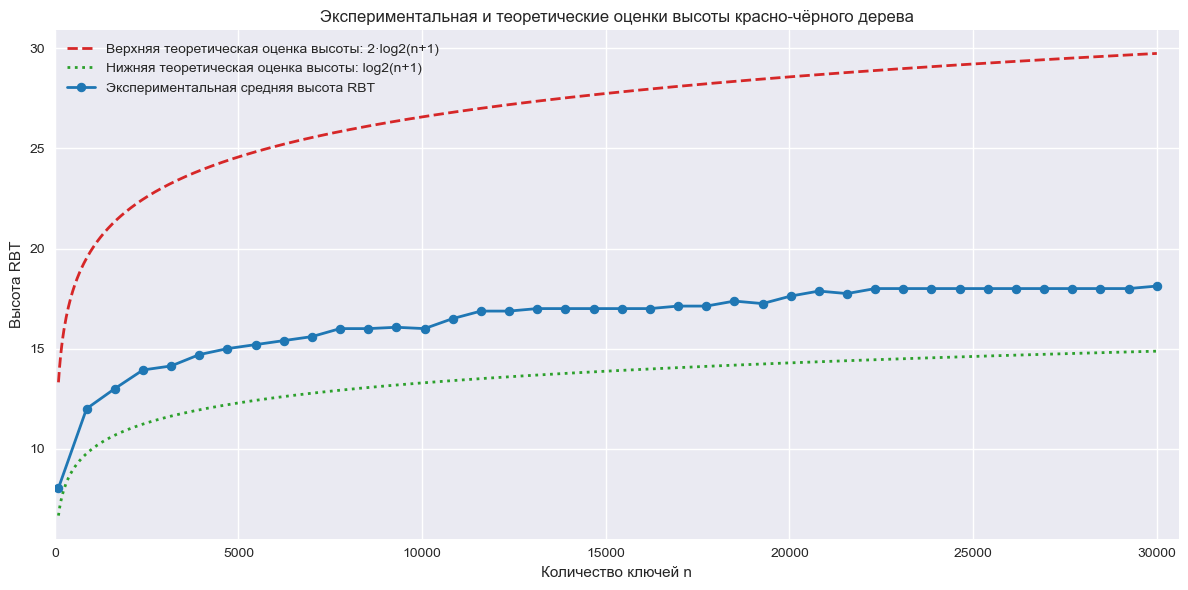


Эмпирическая аппроксимация: h ≈ 1.2358·log2(n) + -0.1136
Теоретические границы: нижняя = log2(n+1), верхняя = 2·log2(n+1).


In [66]:
# Ячейка: эксперимент и график для RedBlackTree (использует класс RedBlackTree из вашей ячейки)
import random
import math
import statistics
import matplotlib.pyplot as plt
import numpy as np
from time import perf_counter

# ---------- Параметры ----------
max_n = 30000
points_count = 40                      # число равномерно распределённых точек
sample_ns = list(map(int, np.linspace(100, max_n, points_count, dtype=int)))
sample_ns = sorted(list(dict.fromkeys(sample_ns)))  # убрать дубликаты, если есть

# адаптивное число повторов: для маленьких n — больше повторов, для больших — меньше
def repeats_for(n):
    if n <= 1000:
        return 60
    if n <= 5000:
        return 30
    if n <= 10000:
        return 15
    return 8

seed = 20251203

# ---------- Вспомогательные функции ----------
def tree_height_rbt(tree):
    """Высота дерева: пустое дерево = 0, узел-лист считается как 1 (считаем количество узлов на пути)."""
    def _h(node):
        # в реализации есть единый NIL-узел; считаем его как "пустоту"
        if node is None:
            return 0
        # если используется NIL sentinel с полем key=None, проверяем по атрибуту
        if getattr(node, "key", None) is None:
            return 0
        left = getattr(node, "left", None)
        right = getattr(node, "right", None)
        return 1 + max(_h(left), _h(right))
    return _h(getattr(tree, "root", None))

def measure_avg_height_rbt(n, repeats, seed_base):
    rng = random.Random(int(seed_base))
    heights = []
    for _ in range(repeats):
        # генерируем n уникальных ключей (равномерно)
        keys = rng.sample(range(1, 10 * n), n)
        tree = RedBlackTree()
        # вставляем ключи
        for k in keys:
            tree.insert(k)
        heights.append(tree_height_rbt(tree))
    return statistics.mean(heights), statistics.pstdev(heights)

# ---------- Измерения ----------
results = []
t0 = perf_counter()
for n in sample_ns:
    reps = repeats_for(n)
    avg_h, std_h = measure_avg_height_rbt(n, reps, seed + int(n))
    results.append((int(n), float(avg_h), float(std_h), int(reps)))
    print(f"n={n:6d}  avg_h={avg_h:6.2f}  std={std_h:5.2f}  repeats={reps}")
t1 = perf_counter()
print(f"Время измерений: {t1-t0:.1f} с")

# ---------- Подготовка данных ----------
x_pts = [r[0] for r in results]
y_pts = [r[1] for r in results]

# теоретические кривые (гладкие)
xs = np.linspace(min(x_pts), max(x_pts), 1000)
# Нижняя теоретическая оценка высоты (идеально сбалансированное дерево)
lower_vals = [math.log2(x + 1) for x in xs]
# Верхняя теоретическая оценка для красно-чёрного дерева: h <= 2 * log2(n+1)
upper_vals = [2.0 * math.log2(x + 1) for x in xs]

# ---------- Построение графика (точки соединены линией) ----------
plt.style.use("seaborn-v0_8")
plt.figure(figsize=(12,6))

# теоретические линии
plt.plot(xs, upper_vals, color='tab:red', linestyle='--', linewidth=2,
         label='Верхняя теоретическая оценка высоты: 2·log2(n+1)')
plt.plot(xs, lower_vals, color='tab:green', linestyle=':', linewidth=2,
         label='Нижняя теоретическая оценка высоты: log2(n+1)')

# экспериментальная линия: точки соединены одной линией и отмечены маркерами
plt.plot(x_pts, y_pts, color='tab:blue', marker='o', linestyle='-', linewidth=2, markersize=6,
         markeredgewidth=0.8, markerfacecolor='tab:blue',
         label='Экспериментальная средняя высота RBT')

plt.xlabel('Количество ключей n')
plt.ylabel('Высота RBT')
plt.title('Экспериментальная и теоретические оценки высоты красно-чёрного дерева')
plt.xlim(0, max(x_pts) * 1.02)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# ---------- Аппроксимация эмпирической константы (опционально) ----------
try:
    log2_vals = np.log2(np.array(x_pts))
    coeffs = np.polyfit(log2_vals, np.array(y_pts), 1)   # h ≈ c * log2(n) + d
    c_emp, d_emp = coeffs[0], coeffs[1]
    print(f"\nЭмпирическая аппроксимация: h ≈ {c_emp:.4f}·log2(n) + {d_emp:.4f}")
    print("Теоретические границы: нижняя = log2(n+1), верхняя = 2·log2(n+1).")
except Exception:
    pass


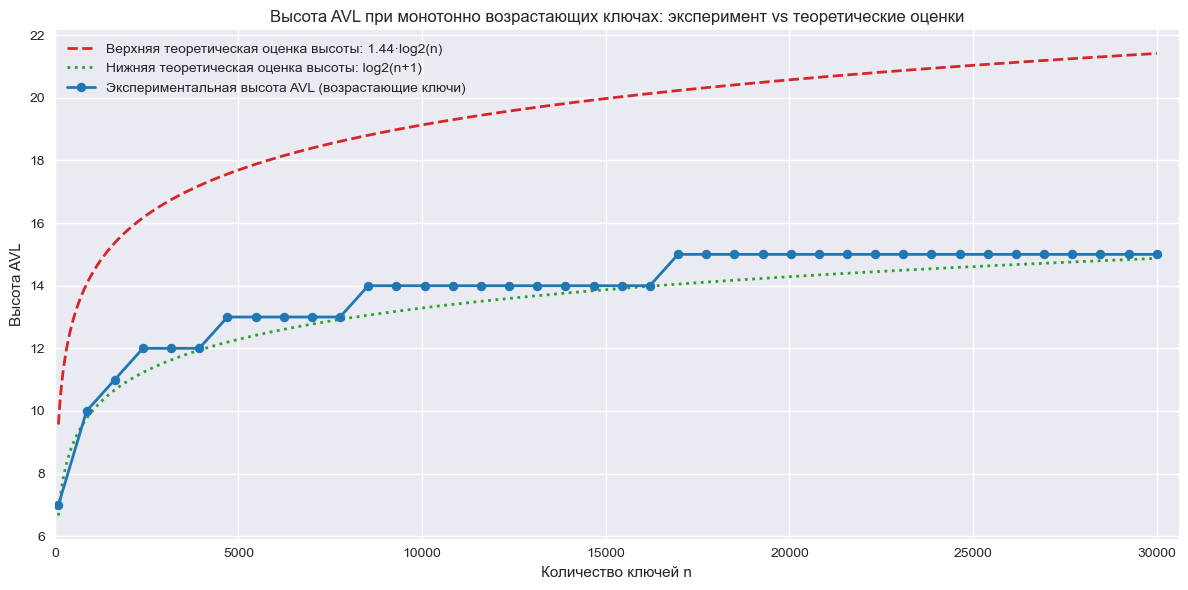

Измерено в 40 точках, время построения: 0.34 с
n	height
100	7
866	10
1633	11
2400	12
3166	12
3933	12
4700	13
5466	13
6233	13
7000	13
7766	13
8533	14
9300	14
10066	14
10833	14
11600	14
12366	14
13133	14
13900	14
14666	14
15433	14
16200	14
16966	15
17733	15
18500	15
19266	15
20033	15
20800	15
21566	15
22333	15
23100	15
23866	15
24633	15
25400	15
26166	15
26933	15
27700	15
28466	15
29233	15
30000	15


In [67]:
# Эксперимент: высота AVL при монотонно возрастающих ключах
import math
import matplotlib.pyplot as plt
import numpy as np
from time import perf_counter

# Параметры
max_n = 30000
points_count = 40
sample_ns = list(map(int, np.linspace(100, max_n, points_count, dtype=int)))
sample_ns = sorted(list(dict.fromkeys(sample_ns)))

# Функция измерения высоты через метод AVLTree.height_of
def avl_height(tree):
    return tree.height_of(getattr(tree, "root", None))

# Построение дерева последовательно (вставляем 1..max_n) и снимаем высоту в контрольных точках
results = []
tree = AVLTree()
tree.root = None

t0 = perf_counter()
next_idx = 0
for i in range(1, max_n + 1):
    tree.insert(i)  # монотонно возрастающие ключи
    if next_idx < len(sample_ns) and i == sample_ns[next_idx]:
        h = avl_height(tree)
        results.append((i, h))
        next_idx += 1
    if next_idx >= len(sample_ns):
        break
t1 = perf_counter()

# Подготовка данных для графика
x_pts = [r[0] for r in results]
y_pts = [r[1] for r in results]

# Теоретические кривые
xs = np.linspace(min(x_pts), max(x_pts), 1000)
upper_vals = [1.44 * math.log2(x) for x in xs]        # верхняя оценка (AVL worst-case)
lower_vals = [math.log2(x + 1) for x in xs]           # нижняя оценка (идеально сбалансированное дерево)

# Построение графика
plt.style.use("seaborn-v0_8")
plt.figure(figsize=(12,6))

# теоретические линии
plt.plot(xs, upper_vals, color='tab:red', linestyle='--', linewidth=2,
         label='Верхняя теоретическая оценка высоты: 1.44·log2(n)')
plt.plot(xs, lower_vals, color='tab:green', linestyle=':', linewidth=2,
         label='Нижняя теоретическая оценка высоты: log2(n+1)')

# экспериментальная линия: точки соединены и отмечены маркерами
plt.plot(x_pts, y_pts, color='tab:blue', marker='o', linestyle='-', linewidth=2, markersize=6,
         markeredgewidth=0.8, markerfacecolor='tab:blue',
         label='Экспериментальная высота AVL (возрастающие ключи)')

plt.xlabel('Количество ключей n')
plt.ylabel('Высота AVL')
plt.title('Высота AVL при монотонно возрастающих ключах: эксперимент vs теоретические оценки')
plt.xlim(0, max(x_pts) * 1.02)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Печать результатов (контрольные точки)
print(f"Измерено в {len(results)} точках, время построения: {t1-t0:.2f} с")
print("n\theight")
for n, h in results:
    print(f"{n}\t{h}")


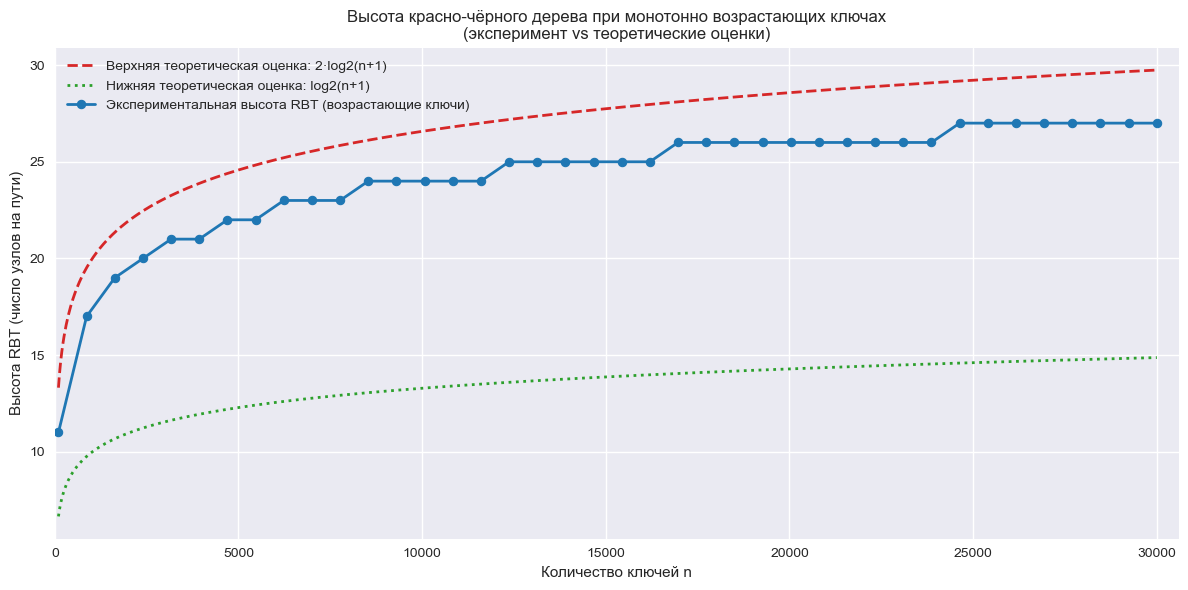

Измерено в 40 точках, время построения: 0.45 с
n	height
100	11
866	17
1633	19
2400	20
3166	21
3933	21
4700	22
5466	22
6233	23
7000	23
7766	23
8533	24
9300	24
10066	24
10833	24
11600	24
12366	25
13133	25
13900	25
14666	25
15433	25
16200	25
16966	26
17733	26
18500	26
19266	26
20033	26
20800	26
21566	26
22333	26
23100	26
23866	26
24633	27
25400	27
26166	27
26933	27
27700	27
28466	27
29233	27
30000	27


In [68]:
# Вставьте эту ячейку сразу после определения класса RedBlackTree и запустите.
import math
import matplotlib.pyplot as plt
import numpy as np
from time import perf_counter

# ---------- Параметры ----------
max_n = 30000
points_count = 40                          # число равномерно распределённых контрольных точек
sample_ns = list(map(int, np.linspace(100, max_n, points_count, dtype=int)))
sample_ns = sorted(list(dict.fromkeys(sample_ns)))  # убрать дубликаты, если есть

# ---------- Вспомогательные функции ----------
def tree_height_rbt(tree):
    """Высота RBT: считаем число узлов на максимальном пути от корня до листа (NIL не учитываем)."""
    def _h(node):
        # sentinel NIL в реализации имеет key == None
        if node is None or getattr(node, "key", None) is None:
            return 0
        return 1 + max(_h(node.left), _h(node.right))
    return _h(getattr(tree, "root", None))

# ---------- Построение дерева монотонно (вставляем 1..max_n) и снятие высоты в контрольных точках ----------
results = []
tree = RedBlackTree()   # используем ваш класс
tree.root = NIL         # явно установить пустое дерево

t0 = perf_counter()
next_idx = 0
for i in range(1, max_n + 1):
    tree.insert(i)  # монотонно возрастающие ключи
    if next_idx < len(sample_ns) and i == sample_ns[next_idx]:
        h = tree_height_rbt(tree)
        results.append((i, h))
        next_idx += 1
    if next_idx >= len(sample_ns):
        break
t1 = perf_counter()

# ---------- Подготовка данных ----------
x_pts = [r[0] for r in results]
y_pts = [r[1] for r in results]

# теоретические кривые (гладкие)
xs = np.linspace(min(x_pts), max(x_pts), 1000)
# Нижняя теоретическая оценка (идеально сбалансированное дерево)
lower_vals = [math.log2(x + 1) for x in xs]
# Верхняя теоретическая оценка для красно-чёрного дерева: h <= 2 * log2(n+1)
upper_vals = [2.0 * math.log2(x + 1) for x in xs]

# ---------- Построение графика ----------
plt.style.use("seaborn-v0_8")
plt.figure(figsize=(12,6))

# теоретические линии
plt.plot(xs, upper_vals, color='tab:red', linestyle='--', linewidth=2,
         label='Верхняя теоретическая оценка: 2·log2(n+1)')
plt.plot(xs, lower_vals, color='tab:green', linestyle=':', linewidth=2,
         label='Нижняя теоретическая оценка: log2(n+1)')

# экспериментальная линия: точки соединены и отмечены маркерами
plt.plot(x_pts, y_pts, color='tab:blue', marker='o', linestyle='-', linewidth=2, markersize=6,
         markeredgewidth=0.8, markerfacecolor='tab:blue',
         label='Экспериментальная высота RBT (возрастающие ключи)')

plt.xlabel('Количество ключей n')
plt.ylabel('Высота RBT (число узлов на пути)')
plt.title('Высота красно-чёрного дерева при монотонно возрастающих ключах\n(эксперимент vs теоретические оценки)')
plt.xlim(0, max(x_pts) * 1.02)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# ---------- Вывод контрольных точек ----------
print(f"Измерено в {len(results)} точках, время построения: {t1-t0:.2f} с")
print("n\theight")
for n, h in results:
    print(f"{n}\t{h}")
